<a href="https://colab.research.google.com/github/imanand002/Applied-ML-Lab/blob/main/ML_Exp8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Experiment 8: Implement a classification model to distinguish between normal and abnormal physiological signals using extracted signal features. (perform comparative analysis on different ML models)


In [8]:
!pip install -q kaggle

# Upload your kaggle.json file when prompted, or place it in ~/.kaggle/
from google.colab import files
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download the MIT-BIH Arrhythmia dataset from Kaggle
!kaggle datasets download -d shayanfazeli/heartbeat
!unzip -q heartbeat.zip -d dataset

Saving mitbih_test.csv.zip to mitbih_test.csv.zip
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/shayanfazeli/heartbeat
License(s): unknown
100% 98.8M/98.8M [00:01<00:00, 71.5MB/s]



Loading datasets...
Extracting features from training and test sets...

--- Training Logistic Regression ---
Accuracy: 0.8516
              precision    recall  f1-score   support

      Normal       0.86      0.99      0.92     18118
    Abnormal       0.75      0.21      0.33      3774

    accuracy                           0.85     21892
   macro avg       0.80      0.60      0.62     21892
weighted avg       0.84      0.85      0.81     21892


--- Training K-Nearest Neighbors ---
Accuracy: 0.8891
              precision    recall  f1-score   support

      Normal       0.91      0.96      0.93     18118
    Abnormal       0.73      0.56      0.64      3774

    accuracy                           0.89     21892
   macro avg       0.82      0.76      0.79     21892
weighted avg       0.88      0.89      0.88     21892


--- Training Support Vector Machine ---
Accuracy: 0.8707
              precision    recall  f1-score   support

      Normal       0.87      0.99      0.93     1811

/tmp/ipykernel_10110/2096424869.py:105: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Accuracy", y="Model", data=summary_df, palette="viridis")


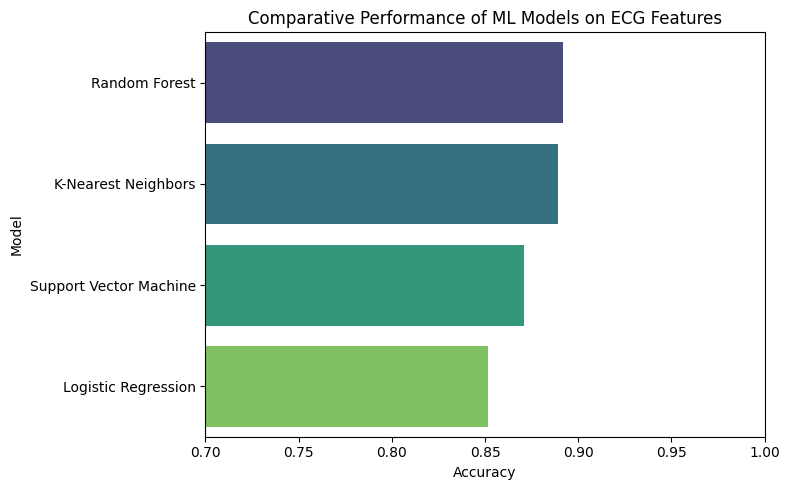

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Load the CSV files directly from your Colab environment
# (Change the filenames below if your uploaded files have different names)
train_path = '/content/dataset/mitbih_train.csv'
test_path = '/content/dataset/mitbih_test.csv'

if not os.path.exists(train_path):
    print(f"'{train_path}' not found in current directory. Let's check what files are available:")
    !ls -la
    raise FileNotFoundError("Please ensure your CSV files are uploaded to the root Colab folder.")

print("Loading datasets...")
train_df = pd.read_csv(train_path, header=None)
test_df = pd.read_csv(test_path, header=None)

# Map multi-class labels to binary: 0 = Normal, 1 = Abnormal (Classes 1-4)
train_df[187] = train_df[187].apply(lambda x: 0 if x == 0 else 1)
test_df[187] = test_df[187].apply(lambda x: 0 if x == 0 else 1)

# 2. Feature Extraction Function
def extract_ecg_features(signal_row):
    """Extracts statistical and morphological features from heartbeat samples."""
    signal = signal_row.values

    mean_val = np.mean(signal)
    std_val = np.std(signal)
    var_val = np.var(signal)
    rms_val = np.sqrt(np.mean(signal**2))
    max_val = np.max(signal)
    min_val = np.min(signal)
    peak_to_peak = max_val - min_val
    energy = np.sum(signal**2)

    # Shannon entropy approximation
    value, counts = np.unique(np.round(signal, 2), return_counts=True)
    probs = counts / counts.sum()
    entropy = -np.sum(probs * np.log2(probs + 1e-10))

    return pd.Series([
        mean_val, std_val, var_val, rms_val,
        max_val, min_val, peak_to_peak,
        energy, entropy
    ])

print("Extracting features from training and test sets...")
feature_cols = [
    'Mean', 'Std', 'Variance', 'RMS',
    'Max', 'Min', 'Peak_to_Peak',
    'Energy', 'Entropy'
]

X_train_features = train_df.iloc[:, :-1].apply(extract_ecg_features, axis=1)
X_train_features.columns = feature_cols
y_train = train_df.iloc[:, -1]

X_test_features = test_df.iloc[:, :-1].apply(extract_ecg_features, axis=1)
X_test_features.columns = feature_cols
y_test = test_df.iloc[:, -1]

# 3. Data Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_features)
X_test_scaled = scaler.transform(X_test_features)

# 4. Model Training & Comparative Evaluation
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine": SVC(kernel='rbf', probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

results = []

for name, model in models.items():
    print(f"\n--- Training {name} ---")
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    results.append({"Model": name, "Accuracy": acc})

    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred, target_names=["Normal", "Abnormal"]))

# 5. Comparative Summary & Plot
summary_df = pd.DataFrame(results).sort_values(by="Accuracy", ascending=False)
print("\n========================================")
print("FINAL COMPARATIVE PERFORMANCE SUMMARY")
print("========================================")
print(summary_df.to_string(index=False))

plt.figure(figsize=(8, 5))
sns.barplot(x="Accuracy", y="Model", data=summary_df, palette="viridis")
plt.title("Comparative Performance of ML Models on ECG Features")
plt.xlim(0.7, 1.0)
plt.tight_layout()
plt.show()